Fetching real MNIST dataset from OpenML (mnist_784)...
Preprocessing subsets...

Starting Training for 20 Epochs (Batch Size: 16)...
Epoch 1/20 | Loss: 0.2048 | Train Accuracy: 13.28%
Epoch 2/20 | Loss: 0.0903 | Train Accuracy: 19.14%
Epoch 3/20 | Loss: 0.0891 | Train Accuracy: 20.31%
Epoch 4/20 | Loss: 0.0885 | Train Accuracy: 16.41%
Epoch 5/20 | Loss: 0.0877 | Train Accuracy: 26.56%
Epoch 6/20 | Loss: 0.0868 | Train Accuracy: 28.91%
Epoch 7/20 | Loss: 0.0854 | Train Accuracy: 31.64%
Epoch 8/20 | Loss: 0.0840 | Train Accuracy: 37.11%
Epoch 9/20 | Loss: 0.0817 | Train Accuracy: 42.19%
Epoch 10/20 | Loss: 0.0789 | Train Accuracy: 48.05%
Epoch 11/20 | Loss: 0.0753 | Train Accuracy: 49.22%
Epoch 12/20 | Loss: 0.0704 | Train Accuracy: 55.08%
Epoch 13/20 | Loss: 0.0649 | Train Accuracy: 59.38%
Epoch 14/20 | Loss: 0.0595 | Train Accuracy: 65.23%
Epoch 15/20 | Loss: 0.0535 | Train Accuracy: 72.27%
Epoch 16/20 | Loss: 0.0477 | Train Accuracy: 80.47%
Epoch 17/20 | Loss: 0.0419 | Train Accuracy:

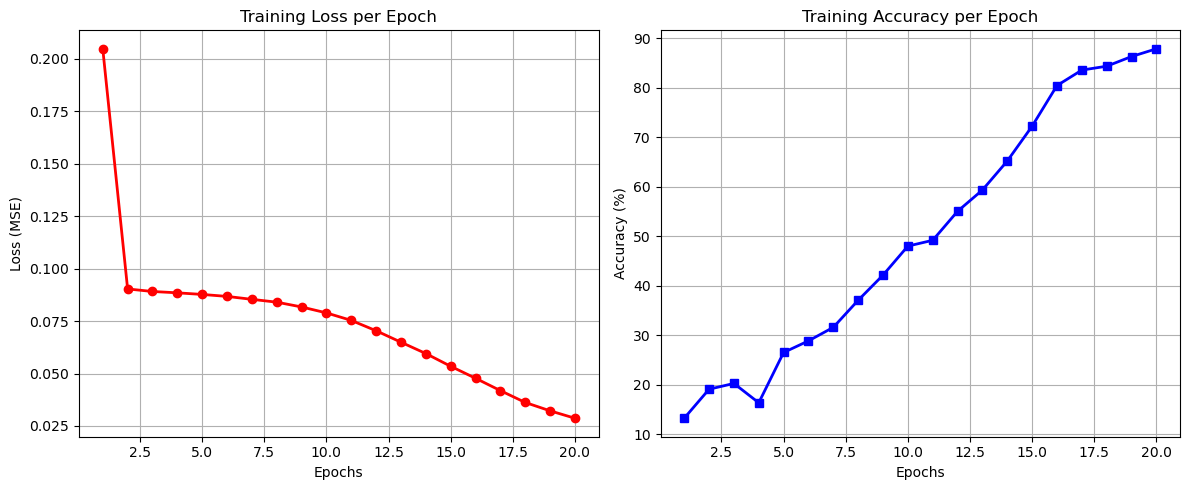

In [5]:


import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

# ==========================================
# 1. CONVOLUTIONAL LAYER (Conv2D)
# ==========================================
class Conv2D:
    def __init__(self, in_channels, out_channels, kernel_size, custom_weights=None, custom_bias=None):
        self.kernel_size = kernel_size
        self.in_channels = in_channels
        self.out_channels = out_channels
        
        if custom_weights is not None:
            self.weights = custom_weights.astype(float)
        else:
            self.weights = np.random.randn(out_channels, in_channels, kernel_size, kernel_size) * np.sqrt(2.0 / (in_channels * kernel_size * kernel_size))
            
        if custom_bias is not None:
            self.biases = custom_bias.astype(float)
        else:
            self.biases = np.zeros((out_channels, 1), dtype=float)
            
        self.dweights = None
        self.dbiases = None

    def forward(self, X):
        self.X = X
        batch_size, in_channels, in_height, in_width = X.shape
        _, _, k_h, k_w = self.weights.shape
        
        out_height = in_height - k_h + 1
        out_width = in_width - k_w + 1
        
        output = np.zeros((batch_size, self.out_channels, out_height, out_width))

        for b in range(batch_size):
            for c_out in range(self.out_channels):
                for h in range(out_height):
                    for w in range(out_width):
                        patch = X[b, :, h:h+k_h, w:w+k_w]
                        output[b, c_out, h, w] = (np.sum(patch * self.weights[c_out]) + self.biases[c_out]).item()
                        
        return output

    def backward(self, d_out, learning_rate=0.01):
        batch_size, _, out_height, out_width = d_out.shape
        _, _, k_h, k_w = self.weights.shape
        
        dX = np.zeros_like(self.X, dtype=float)
        self.dweights = np.zeros_like(self.weights, dtype=float)
        self.dbiases = np.zeros_like(self.biases, dtype=float)

        for b in range(batch_size):
            for c_out in range(self.out_channels):
                for h in range(out_height):
                    for w in range(out_width):
                        patch = self.X[b, :, h:h+k_h, w:w+k_w]
                        self.dweights[c_out] += patch * d_out[b, c_out, h, w]
                        dX[b, :, h:h+k_h, w:w+k_w] += self.weights[c_out] * d_out[b, c_out, h, w]
                self.dbiases[c_out] += np.sum(d_out[b, c_out, :, :])

        self.weights -= learning_rate * self.dweights
        self.biases -= learning_rate * self.dbiases

        return dX


# ==========================================
# 2. RELU ACTIVATION LAYER
# ==========================================
class ReLU:
    def forward(self, X):
        self.X = X
        return np.maximum(0, X)

    def backward(self, d_out):
        return d_out * (self.X > 0)


# ==========================================
# 3. MAX POOLING LAYER (MaxPool2D)
# ==========================================
class MaxPool2D:
    def __init__(self, pool_size=2, stride=2):
        self.pool_size = pool_size
        self.stride = stride

    def forward(self, X):
        self.X = X
        batch_size, channels, in_height, in_width = X.shape
        p_size = self.pool_size
        
        out_height = (in_height - p_size) // self.stride + 1
        out_width = (in_width - p_size) // self.stride + 1
        
        output = np.zeros((batch_size, channels, out_height, out_width))

        for b in range(batch_size):
            for c in range(channels):
                for h in range(out_height):
                    for w in range(out_width):
                        h_start = h * self.stride
                        h_end = h_start + p_size
                        w_start = w * self.stride
                        w_end = w_start + p_size
                        
                        patch = X[b, c, h_start:h_end, w_start:w_end]
                        output[b, c, h, w] = np.max(patch)
                        
        return output

    def backward(self, d_out):
        batch_size, channels, in_height, in_width = self.X.shape
        dX = np.zeros_like(self.X, dtype=float)
        p_size = self.pool_size

        for b in range(batch_size):
            for c in range(channels):
                for h in range(d_out.shape[2]):
                    for w in range(d_out.shape[3]):
                        h_start = h * self.stride
                        h_end = h_start + p_size
                        w_start = w * self.stride
                        w_end = w_start + p_size
                        
                        patch = self.X[b, c, h_start:h_end, w_start:w_end]
                        mask = (patch == np.max(patch))
                        dX[b, c, h_start:h_end, w_start:w_end] += mask * d_out[b, c, h, w]
                        
        return dX


# ==========================================
# 4. FLATTEN LAYER
# ==========================================
class Flatten:
    def forward(self, X):
        self.original_shape = X.shape
        batch_size = X.shape[0]
        return X.reshape(batch_size, -1)

    def backward(self, d_out):
        return d_out.reshape(self.original_shape)


# ==========================================
# 5. FULLY CONNECTED LAYER WITH SIGMOID
# ==========================================
class FullyConnectedWithSigmoid:
    def __init__(self, input_dim, output_dim):
        np.random.seed(42)
        self.weights = np.random.randn(input_dim, output_dim) * np.sqrt(2.0 / input_dim)
        self.biases = np.zeros((1, output_dim), dtype=float)
        self.X = None
        self.A2 = None  
        self.dweights = None
        self.dbiases = None

    def sigmoid(self, Z):
        return 1 / (1 + np.exp(-np.clip(Z, -500, 500)))

    def forward(self, X):
        self.X = X
        Z2 = np.dot(X, self.weights) + self.biases
        self.A2 = self.sigmoid(Z2)
        return self.A2

    def backward(self, d_out, learning_rate=0.01):
        dZ2 = d_out * self.A2 * (1 - self.A2)
        self.dweights = np.dot(self.X.T, dZ2)
        self.dbiases = np.sum(dZ2, axis=0, keepdims=True)
        dX = np.dot(dZ2, self.weights.T)

        self.weights -= learning_rate * self.dweights
        self.biases -= learning_rate * self.dbiases

        return dX


# ==========================================
# 6. DATA PREPROCESSING & UTILS
# ==========================================
def preprocess_data(images, labels, num_samples=None):
    if num_samples is not None:
        images = images[:num_samples]
        labels = labels[:num_samples]
        
    X = images.astype(float) / 255.0
    if len(X.shape) == 2 or X.shape[1] == 784:
        X = X.reshape(-1, 1, 28, 28)
        
    y_int = labels.astype(int)
    Y = np.zeros((y_int.size, 10))
    Y[np.arange(y_int.size), y_int] = 1.0
    return X, Y


def evaluate_accuracy(X, y_true, conv, relu, maxpool, flatten, fc, max_samples=100):
    correct = 0
    total = min(len(X), max_samples)
    
    for i in range(total):
        img = X[i:i+1]
        label_onehot = y_true[i]
        
        out = conv.forward(img)
        out = relu.forward(out)
        out = maxpool.forward(out)
        out = flatten.forward(out)
        preds = fc.forward(out)
        
        if np.argmax(preds) == np.argmax(label_onehot):
            correct += 1
            
    return (correct / total) * 100


# ==========================================
# 7. MAIN TRAINING & PLOTTING SCRIPT
# ==========================================
if __name__ == "__main__":
    print("Fetching real MNIST dataset from OpenML (mnist_784)...")
    mnist = fetch_openml('mnist_784', version=1, as_frame=False, cache=True)
    X_raw, y_raw = mnist.data, mnist.target
    
    # Subsetting for pure NumPy loop performance demonstration
    TRAIN_LIMIT = 256
    TEST_LIMIT = 64

    print("Preprocessing subsets...")
    X_train, Y_train = preprocess_data(X_raw[:60000], y_raw[:60000], num_samples=TRAIN_LIMIT)
    X_test, Y_test = preprocess_data(X_raw[60000:], y_raw[60000:], num_samples=TEST_LIMIT)

    # Initialize Layers
    conv = Conv2D(in_channels=1, out_channels=2, kernel_size=3)
    relu = ReLU()
    maxpool = MaxPool2D(pool_size=2, stride=2)
    flatten = Flatten()
    fc = FullyConnectedWithSigmoid(input_dim=2 * 13 * 13, output_dim=10)

    # Hyperparameters for 10 Epochs
    EPOCHS = 20
    BATCH_SIZE = 16
    LEARNING_RATE = 0.01

    train_loss_history = []
    train_acc_history = []

    print(f"\nStarting Training for {EPOCHS} Epochs (Batch Size: {BATCH_SIZE})...")

    for epoch in range(EPOCHS):
        permutation = np.random.permutation(X_train.shape[0])
        X_train_shuffled = X_train[permutation]
        Y_train_shuffled = Y_train[permutation]
        
        epoch_loss = 0.0
        num_batches = X_train.shape[0] // BATCH_SIZE

        for b in range(num_batches):
            start_idx = b * BATCH_SIZE
            end_idx = start_idx + BATCH_SIZE
            
            X_batch = X_train_shuffled[start_idx:end_idx]
            Y_batch = Y_train_shuffled[start_idx:end_idx]

            # Forward Pass
            out_conv = conv.forward(X_batch)
            out_relu = relu.forward(out_conv)
            out_pool = maxpool.forward(out_relu)
            out_flat = flatten.forward(out_pool)
            preds = fc.forward(out_flat)

            # Loss Calculation (MSE)
            loss = np.mean((preds - Y_batch) ** 2)
            epoch_loss += loss

            # Backward Pass
            d_out = preds - Y_batch 
            d_fc = fc.backward(d_out, learning_rate=LEARNING_RATE)
            d_flat = flatten.backward(d_fc)
            d_relu = maxpool.backward(d_flat)
            d_conv = relu.backward(d_relu)
            _ = conv.backward(d_conv, learning_rate=LEARNING_RATE)

        avg_loss = epoch_loss / num_batches
        train_acc = evaluate_accuracy(X_train, Y_train, conv, relu, maxpool, flatten, fc, max_samples=TRAIN_LIMIT)
        
        train_loss_history.append(avg_loss)
        train_acc_history.append(train_acc)
        
        print(f"Epoch {epoch + 1}/{EPOCHS} | Loss: {avg_loss:.4f} | Train Accuracy: {train_acc:.2f}%")

    print("==================================================")
    print("         UPDATED WEIGHTS & BIASES (FINAL)         ")
    print("==================================================")
    print(f"1. Updated Conv Weights (W1_new):\n{conv.weights[0, 0]}\n")
    print(f"   Updated Conv Bias (b1_new):\n{conv.biases}\n")
    print(f"2. Updated FC Weights Shape (W2_new): {fc.weights.shape}")
    print(f"   Updated FC Biases (b2_new):\n{fc.biases}\n")
   

    # Final Test Accuracy
    test_acc = evaluate_accuracy(X_test, Y_test, conv, relu, maxpool, flatten, fc, max_samples=TEST_LIMIT)
    print(f"Final Test Set Accuracy: {test_acc:.2f}%")

    # ==========================================
    # 8. DRAW GRAPHS USING MATPLOTLIB
    # ==========================================
    plt.figure(figsize=(12, 5))

    # Loss Plot
    plt.subplot(1, 2, 1)
    plt.plot(range(1, EPOCHS + 1), train_loss_history, marker='o', color='red', linewidth=2)
    plt.title('Training Loss per Epoch')
    plt.xlabel('Epochs')
    plt.ylabel('Loss (MSE)')
    plt.grid(True)

    # Accuracy Plot
    plt.subplot(1, 2, 2)
    plt.plot(range(1, EPOCHS + 1), train_acc_history, marker='s', color='blue', linewidth=2)
    plt.title('Training Accuracy per Epoch')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.grid(True)

    plt.tight_layout()
    plt.show()